## 1. Setup and data

**Metric.** Only about 13% of countries are Low HDI, so plain accuracy would reward a model that ignores them. We select models on **macro F1**, which gives each class equal weight.

**Protocol.** Tuning uses 5-fold stratified CV on the training set only. The model is picked on the validation set, refitted on train + validation, and scored once on the test set. All randomness uses seed 42.

**Leakage.** `HDI` is the raw score the label is built from, so it is kept out of the features (checked by an assert below).

In [ ]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, cross_validate)
from sklearn.tree import DecisionTreeClassifier, export_text

# The majority baseline never predicts two of the classes, which makes their F1 undefined (counted as 0).
# That is expected, so we hide the warning.
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)

SEED = 42
CLASS_NAMES = ["Low", "Medium/High", "Very High"]
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # reused for every CV below


def load_split(prefix, kind):
    # Read one CSV; return features, class label and the raw HDI score
    df = pd.read_csv(f"{prefix}_{kind}_features.csv", index_col=["ISO", "Country Name"])
    return df.drop(columns=["HDI", "HDIClass"]).astype(float), df["HDIClass"].astype(int), df["HDI"]


X_train, y_train, hdi_train = load_split("train", "scaled")
X_val, y_val, hdi_val = load_split("val", "scaled")
X_test, y_test, hdi_test = load_split("test", "scaled")
Xp_train, yp_train, _ = load_split("train", "pca")
Xp_val, yp_val, _ = load_split("val", "pca")
Xp_test, yp_test, _ = load_split("test", "pca")

print(f"Scaled: train {X_train.shape}, val {X_val.shape}, test {X_test.shape}")
print(f"PCA   : train {Xp_train.shape}, val {Xp_val.shape}, test {Xp_test.shape}")

split_counts = pd.DataFrame({"Train": y_train.value_counts().sort_index(),
                             "Val": y_val.value_counts().sort_index(),
                             "Test": y_test.value_counts().sort_index()})
split_counts.index = [f"{i} - {n}" for i, n in enumerate(CLASS_NAMES)]
split_counts.loc["Total"] = split_counts.sum()
display(split_counts)

# Column groups, used for the feature comparison in section 5
missing_cols = [c for c in X_train.columns if c.startswith("Missing_")]
region_cols = [c for c in X_train.columns if c.startswith("Region_")]
sector_cols = [c for c in X_train.columns if c.startswith("DominantSector_")]
categorical_cols = region_cols + sector_cols
numeric_cols = [c for c in X_train.columns if c not in missing_cols + categorical_cols]
assert len(numeric_cols) + len(missing_cols) + len(categorical_cols) == X_train.shape[1]


def summarise(y_true, y_pred):
    # The three headline metrics
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
            "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0)}


def per_class_report(y_true, y_pred):
    # Precision / recall / F1 per class
    rep = classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES,
                                output_dict=True, zero_division=0)
    return pd.DataFrame(rep).T.loc[CLASS_NAMES + ["macro avg", "weighted avg"]]

Scaled: train (115, 31), val (38, 31), test (39, 31)
PCA   : train (115, 12), val (38, 12), test (39, 12)


,Train,Val,Test
0 - Low,16,5,5
1 - Medium/High,55,18,19
2 - Very High,44,15,15
Total,115,38,39


The classes are stratified, so every split has the same mix. The thing to remember is that the validation and test sets each hold only **5 Low-HDI countries**. One wrong prediction there swings that class's recall by 20 points, so Low-class numbers will be jumpy.

## 2. Default models

First a quick look at each model with default-ish settings. The majority baseline always predicts Medium/High and is the bar any real model has to clear. The gap between train and CV score shows how much a model overfits.

Logistic regression uses `max_iter=2000` so it converges. The forest uses 300 trees.

In [2]:
default_models = {
    "Majority": DummyClassifier(strategy="most_frequent"),
    "LogReg": LogisticRegression(max_iter=2000, random_state=SEED),
    "Tree": DecisionTreeClassifier(random_state=SEED),
    "RF": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}

rows = []
for name, model in default_models.items():
    res = cross_validate(model, X_train, y_train, cv=cv5, scoring=["accuracy", "f1_macro"], return_train_score=True)
    rows.append({"Model": name, "Train F1": res["train_f1_macro"].mean(), "CV F1": res["test_f1_macro"].mean(),
                 "CV std": res["test_f1_macro"].std(), "CV Acc": res["test_accuracy"].mean()})

default_cv_df = pd.DataFrame(rows).set_index("Model")
default_cv_df["Overfit gap"] = default_cv_df["Train F1"] - default_cv_df["CV F1"]
display(default_cv_df.round(3))

,Train F1,CV F1,CV std,CV Acc,Overfit gap
Model,,,,,
Majority,0.216,0.216,0.000,0.478,0.000
LogReg,0.975,0.928,0.066,0.930,0.047
Tree,1.000,0.851,0.102,0.852,0.149
RF,1.000,0.856,0.137,0.896,0.144


## 3. Tuning and model selection

The grids are small on purpose. There are only about 115 training countries, so a big search would just fit the CV folds.

| Model | What we tune |
|---|---|
| LogReg | `C` (regularisation strength) and `class_weight` |
| Tree | split criterion, `max_depth`, `min_samples_leaf` |
| RF | `max_depth`, `min_samples_leaf`, `max_features`, `class_weight` (300 trees fixed) |

Each grid is scored by CV macro F1 on the training set. Then the three tuned models predict the **validation set**, and the best macro F1 wins (CV score breaks ties). The best CV score from a grid search is a little optimistic because it is a maximum over many tries, which is why the validation check matters.

In [3]:
search_spaces = {
    "LogReg": (LogisticRegression(max_iter=2000, random_state=SEED),
               {"C": [0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced"]}),
    "Tree": (DecisionTreeClassifier(random_state=SEED),
             {"criterion": ["gini", "entropy"], "max_depth": [2, 3, 4, 5, None], "min_samples_leaf": [1, 3, 5, 10]}),
    "RF": (RandomForestClassifier(n_estimators=300, random_state=SEED),
           {"max_depth": [3, 5, None], "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", 0.5],
            "class_weight": [None, "balanced"]}),
}

tuned, tuning_rows = {}, []
for name, (estimator, grid) in search_spaces.items():
    gs = GridSearchCV(estimator, grid, scoring="f1_macro", cv=cv5, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    tuning_rows.append({"Model": name, "Best params": gs.best_params_, "CV F1": gs.best_score_,
                        "CV std": gs.cv_results_["std_test_score"][gs.best_index_]})
display(pd.DataFrame(tuning_rows).set_index("Model"))

# Top 5 settings per model, to see how flat the search is
for name, gs in tuned.items():
    top = (pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").head(5)
           [["params", "mean_test_score", "std_test_score"]]
           .rename(columns={"mean_test_score": "CV F1", "std_test_score": "CV std"}).reset_index(drop=True))
    print(f"Top 5 - {name}")
    display(top)

,Best params,CV F1,CV std
Model,,,
LogReg,"{'C': 1, 'class_weight': None}",0.928,0.066
Tree,"{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1}",0.851,0.102
RF,"{'class_weight': None, 'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 1}",0.893,0.065


Top 5 - LogReg


,params,CV F1,CV std
0,"{'C': 1, 'class_weight': None}",0.928,0.066
1,"{'C': 0.1, 'class_weight': None}",0.914,0.060
2,"{'C': 1, 'class_weight': 'balanced'}",0.910,0.052
3,"{'C': 10, 'class_weight': 'balanced'}",0.902,0.051
4,"{'C': 10, 'class_weight': None}",0.896,0.050


Top 5 - Tree


,params,CV F1,CV std
0,"{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1}",0.851,0.102
1,"{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1}",0.834,0.081
2,"{'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 1}",0.834,0.081
3,"{'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 3}",0.830,0.070
4,"{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 3}",0.830,0.070


Top 5 - RF


,params,CV F1,CV std
0,"{'class_weight': None, 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}",0.893,0.065
1,"{'class_weight': None, 'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 1}",0.893,0.065
2,"{'class_weight': 'balanced', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1}",0.891,0.073
3,"{'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2}",0.891,0.073
4,"{'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1}",0.885,0.067


In [4]:
# Validation-set check of the tuned models (fitted on train only)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
val_rows = {"Majority": summarise(y_val, baseline.predict(X_val))}
for name, gs in tuned.items():
    val_rows[name] = summarise(y_val, gs.best_estimator_.predict(X_val))
val_df = pd.DataFrame(val_rows).T
display(val_df)

# Pick the best validation macro F1; ties go to the better CV score
candidates = val_df.drop(index="Majority").copy()
candidates["CV F1"] = [tuned[n].best_score_ for n in candidates.index]
selected = candidates.sort_values(["Macro F1", "CV F1"], ascending=False).index[0]
print(f"Selected on validation: {selected}")

,Accuracy,Balanced Acc,Macro F1
Majority,0.474,0.333,0.214
LogReg,0.711,0.604,0.592
Tree,0.763,0.633,0.639
RF,0.737,0.619,0.619


Selected on validation: Tree


With 38 validation countries, differences of a few hundredths are within noise, so treat the choice as "good enough" rather than decisive.

## 4. Test evaluation

The chosen hyperparameters are kept and each model is refitted on train + validation (153 countries) before predicting the test set. This is the first time the test set is touched. The model picked in section 3 is the official final model, and that choice was made before seeing any test number. The other models are shown for comparison.

,Accuracy,Balanced Acc,Macro F1
Majority,0.487,0.333,0.218
LogReg,0.795,0.752,0.784
Tree,0.718,0.695,0.727
RF,0.846,0.792,0.822


--- LogReg ---


,precision,recall,f1-score,support
Low,1.000,0.600,0.750,5.0
Medium/High,0.789,0.789,0.789,19.0
Very High,0.765,0.867,0.812,15.0
macro avg,0.851,0.752,0.784,39.0
weighted avg,0.807,0.795,0.793,39.0


--- Tree (selected) ---


,precision,recall,f1-score,support
Low,1.000,0.600,0.750,5.0
Medium/High,0.722,0.684,0.703,19.0
Very High,0.667,0.800,0.727,15.0
macro avg,0.796,0.695,0.727,39.0
weighted avg,0.736,0.718,0.718,39.0


--- RF ---


,precision,recall,f1-score,support
Low,1.000,0.600,0.750,5.0
Medium/High,0.842,0.842,0.842,19.0
Very High,0.824,0.933,0.875,15.0
macro avg,0.889,0.792,0.822,39.0
weighted avg,0.855,0.846,0.843,39.0


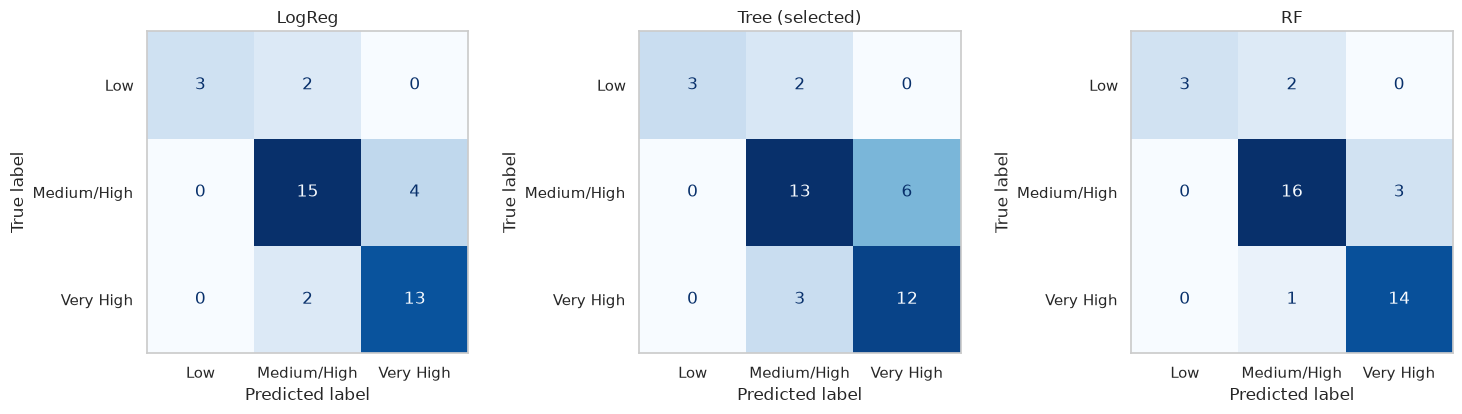

In [5]:
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

# clone() keeps the tuned hyperparameters but drops the fitted state, so each model is refitted on train+val
final_models = {"Majority": clone(baseline).fit(X_trval, y_trval)}
for name, gs in tuned.items():
    final_models[name] = clone(gs.best_estimator_).fit(X_trval, y_trval)

test_preds = {name: m.predict(X_test) for name, m in final_models.items()}
test_df = pd.DataFrame({name: summarise(y_test, p) for name, p in test_preds.items()}).T
display(test_df)

for name in ["LogReg", "Tree", "RF"]:
    print(f"--- {name}{' (selected)' if name == selected else ''} ---")
    display(per_class_report(y_test, test_preds[name]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, name in zip(axes, ["LogReg", "Tree", "RF"]):
    ConfusionMatrixDisplay.from_predictions(y_test, test_preds[name], labels=[0, 1, 2], display_labels=CLASS_NAMES,
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name + (" (selected)" if name == selected else ""))
    ax.grid(False)
plt.tight_layout()
plt.show()

Rows of the confusion matrix are the true class and columns the predicted class. The classes are ordered, so mixing up neighbours (say Medium/High and Very High) is a milder mistake than confusing Low with Very High. With only 39 test countries, one error is about 2.6 points of accuracy, so small gaps between models don't mean much.

## 5. Feature groups and PCA

**Feature groups.** Does region or the engineered dominant sector add anything on top of the numeric indicators? We compare subsets for the tuned LogReg and RF using 5-fold CV repeated 3 times on train + validation, which is steadier than a single run. (The hyperparameters were tuned on all features, which may slightly favour that set.)

,LogReg,RF
Numeric only,0.766 ± 0.068,0.808 ± 0.079
Categorical only,0.538 ± 0.076,0.543 ± 0.071
Numeric + missing,0.799 ± 0.08,0.812 ± 0.07
Numeric + Region,0.81 ± 0.067,0.811 ± 0.064
Numeric + Sector,0.786 ± 0.072,0.818 ± 0.066
Numeric + Region + Sector,0.817 ± 0.065,0.828 ± 0.063
All,0.818 ± 0.05,0.822 ± 0.068


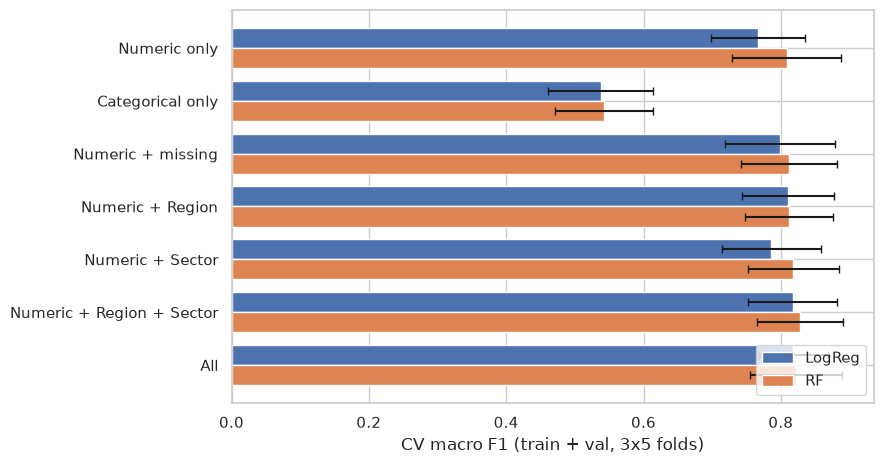

In [6]:
feature_sets = {
    "Numeric only": numeric_cols,
    "Categorical only": categorical_cols,
    "Numeric + missing": numeric_cols + missing_cols,
    "Numeric + Region": numeric_cols + region_cols,
    "Numeric + Sector": numeric_cols + sector_cols,
    "Numeric + Region + Sector": numeric_cols + categorical_cols,
    "All": list(X_train.columns),
}

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

fs_mean, fs_std = {}, {}
for model_name in ["LogReg", "RF"]:
    fs_mean[model_name], fs_std[model_name] = {}, {}
    for fs_name, cols in feature_sets.items():
        est = clone(tuned[model_name].best_estimator_)
        scores = cross_val_score(est, X_trval[cols], y_trval, cv=rcv, scoring="f1_macro", n_jobs=-1)
        fs_mean[model_name][fs_name] = scores.mean()
        fs_std[model_name][fs_name] = scores.std()

fs_mean, fs_std = pd.DataFrame(fs_mean), pd.DataFrame(fs_std)
display(fs_mean.round(3).astype(str) + " ± " + fs_std.round(3).astype(str))

fig, ax = plt.subplots(figsize=(9, 4.8))
y_pos, h = np.arange(len(fs_mean)), 0.38
ax.barh(y_pos - h / 2, fs_mean["LogReg"], h, xerr=fs_std["LogReg"], label="LogReg", capsize=3)
ax.barh(y_pos + h / 2, fs_mean["RF"], h, xerr=fs_std["RF"], label="RF", capsize=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(fs_mean.index)
ax.invert_yaxis()
ax.set_xlabel("CV macro F1 (train + val, 3x5 folds)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Use the "Numeric only" row as the reference. If adding Region or Sector moves the score by less than the fold-to-fold spread (the ± part), there's no real evidence it helps. `DominantSector` is built from the agriculture and industry shares, which are already numeric predictors, so it can't carry new information.

**PCA.** Next, do the PCA components (95% of the training variance) do better or worse than the original standardised features? We reuse the same tuned settings for both, which keeps it simple but could slightly favour the non-PCA side.

In [7]:
pca_rows = []
for name, gs in tuned.items():
    for label, (Xtr, Xva) in {"Scaled": (X_train, X_val), "PCA": (Xp_train, Xp_val)}.items():
        est = clone(gs.best_estimator_)
        cv_scores = cross_val_score(est, Xtr, y_train, cv=cv5, scoring="f1_macro", n_jobs=-1)
        val_f1 = f1_score(y_val, clone(est).fit(Xtr, y_train).predict(Xva), average="macro", zero_division=0)
        pca_rows.append({"Model": name, "Features": label, "n_cols": Xtr.shape[1],
                         "CV F1": cv_scores.mean(), "CV std": cv_scores.std(), "Val F1": val_f1})

display(pd.DataFrame(pca_rows).set_index(["Model", "Features"]).round(3))

n_cols  CV F1  CV std  Val F1
Model  Features                               
LogReg Scaled        31  0.928   0.066   0.592
       PCA           12  0.914   0.063   0.612
Tree   Scaled        31  0.851   0.102   0.639
       PCA           12  0.809   0.096   0.496
RF     Scaled        31  0.893   0.065   0.619
       PCA           12  0.846   0.122   0.557

PCA keeps the directions with the most variance, not necessarily the ones that separate the classes, and it makes the model harder to read. With about 30 features and 150 countries it isn't needed to fight overfitting.


## 6. Interpretation and errors

- **Logistic regression coefficients.** Many indicators move together (electricity, internet use and infant mortality all track development), so individual coefficients can be unstable. Read them as associations, not separate effects. The heatmap below shows how correlated the top numeric features are.
- **Random forest permutation importance.** Shuffle one feature at a time on the test set and see how much macro F1 drops. This is done after all modelling decisions, so it informs interpretation only.
- **Errors.** For the selected model we list the misclassified test countries, with the distance from their true HDI to the nearest class boundary (0.550 or 0.800). Countries sitting right on a boundary are naturally hard to call.

Top 12 features by max |coef|:


,Low,Medium/High,Very High,max_abs
NV.AGR.TOTL.ZS,1.424,0.403,-1.827,1.827
SP.DYN.IMRT.IN,1.128,0.431,-1.559,1.559
IT.NET.USER.ZS,-0.454,-0.935,1.389,1.389
EG.ELC.ACCS.ZS,-0.970,0.522,0.448,0.970
"Region_Middle East, North Africa, Afghanistan & Pakistan",0.880,-0.290,-0.590,0.880
NV.IND.TOTL.ZS,-0.711,0.092,0.619,0.711
ServiceSector,-0.357,-0.330,0.687,0.687
Missing_NE.TRD.GNFS.ZS,-0.679,0.300,0.378,0.679
Region_East Asia & Pacific,-0.648,0.670,-0.022,0.670
Missing_FP.CPI.TOTL.ZG,0.109,0.378,-0.487,0.487


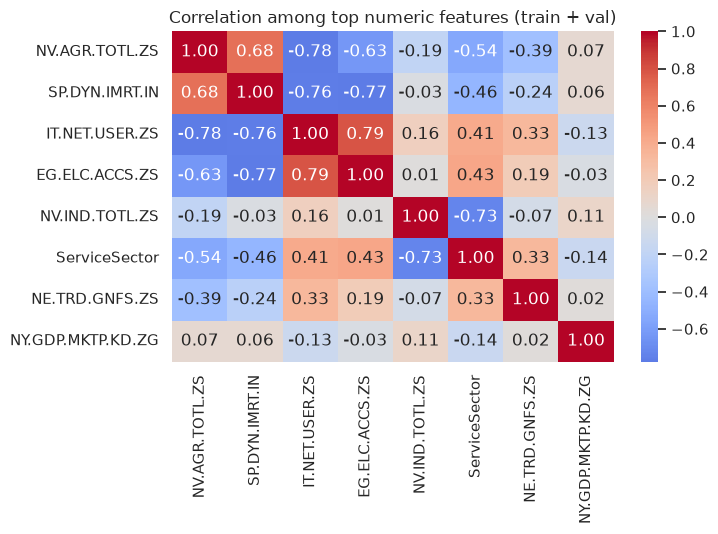

Top 12 features by permutation importance (RF, macro F1):


,Importance mean,Importance std
SP.DYN.IMRT.IN,2.213e-01,0.079
EG.ELC.ACCS.ZS,1.113e-01,0.047
NV.AGR.TOTL.ZS,4.190e-02,0.050
IT.NET.USER.ZS,2.720e-02,0.046
SL.UEM.TOTL.ZS,2.600e-03,0.007
Missing_FP.CPI.TOTL.ZG,6.000e-04,0.004
Missing_EG.ELC.ACCS.ZS,0.000e+00,0.000
Missing_SL.UEM.TOTL.ZS,0.000e+00,0.000
Missing_NV.IND.TOTL.ZS,0.000e+00,0.000
Missing_IT.NET.USER.ZS,0.000e+00,0.000


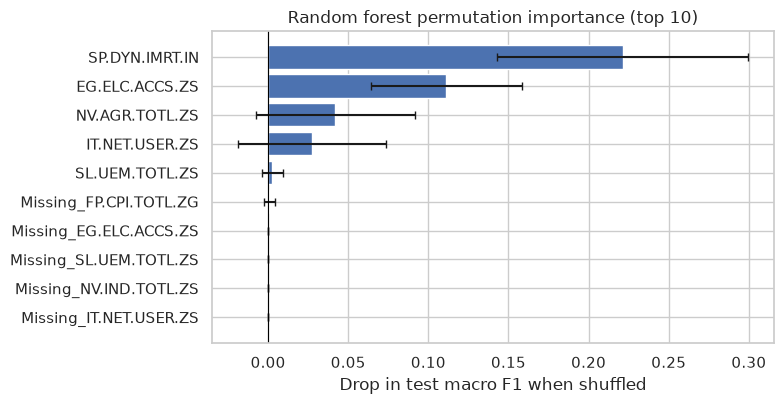

Misclassified test countries (Tree): 11 / 39


,,HDI,True,Pred,P(Low),P(Med/High),P(Very High),Dist to boundary
ISO,Country Name,,,,,,,
MDV,Maldives,0.766,Medium/High,Very High,0.0,0.0,1.0,0.034
VNM,Viet Nam,0.766,Medium/High,Very High,0.0,0.0,1.0,0.034
BGR,Bulgaria,0.845,Very High,Medium/High,0.0,1.0,0.0,0.045
LBN,Lebanon,0.752,Medium/High,Very High,0.0,0.0,1.0,0.048
ATG,Antigua and Barbuda,0.851,Very High,Medium/High,0.0,1.0,0.0,0.051
MNG,Mongolia,0.747,Medium/High,Very High,0.0,0.0,1.0,0.053
MDG,Madagascar,0.487,Low,Medium/High,0.0,1.0,0.0,0.063
BWA,Botswana,0.731,Medium/High,Very High,0.0,0.0,1.0,0.069
SUR,Suriname,0.722,Medium/High,Very High,0.0,0.0,1.0,0.078


Median distance to a class boundary: 0.053 for the errors vs 0.066 for all test countries.

Decision tree rules (train + val):
|--- SP.DYN.IMRT.IN <= -0.64
|   |--- IT.NET.USER.ZS <= 0.48
|   |   |--- FP.CPI.TOTL.ZG <= -0.36
|   |   |   |--- class: 2
|   |   |--- FP.CPI.TOTL.ZG >  -0.36
|   |   |   |--- class: 1
|   |--- IT.NET.USER.ZS >  0.48
|   |   |--- FP.CPI.TOTL.ZG <= -0.60
|   |   |   |--- class: 1
|   |   |--- FP.CPI.TOTL.ZG >  -0.60
|   |   |   |--- SL.UEM.TOTL.ZS <= -0.98
|   |   |   |   |--- IT.NET.USER.ZS <= 0.95
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- IT.NET.USER.ZS >  0.95
|   |   |   |   |   |--- class: 2
|   |   |   |--- SL.UEM.TOTL.ZS >  -0.98
|   |   |   |   |--- class: 2
|--- SP.DYN.IMRT.IN >  -0.64
|   |--- NV.AGR.TOTL.ZS <= 1.79
|   |   |--- NV.AGR.TOTL.ZS <= -0.80
|   |   |   |--- IT.NET.USER.ZS <= -0.12
|   |   |   |   |--- NY.GDP.MKTP.KD.ZG <= 0.58
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- NY.GDP.MKTP.KD.ZG >  0.58
|   |   |   |   |  

In [8]:
# 1. Logistic regression coefficients (final model, train + val)
coef_df = pd.DataFrame(final_models["LogReg"].coef_.T, index=X_trval.columns, columns=CLASS_NAMES)
coef_df["max_abs"] = coef_df.abs().max(axis=1)
print("Top 12 features by max |coef|:")
display(coef_df.sort_values("max_abs", ascending=False).head(12).round(3))

top_num = [c for c in coef_df.sort_values("max_abs", ascending=False).index if c in numeric_cols][:8]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(X_trval[top_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation among top numeric features (train + val)")
plt.tight_layout()
plt.show()

# 2. Random forest permutation importance on the test set
pi = permutation_importance(final_models["RF"], X_test, y_test, scoring="f1_macro",
                            n_repeats=30, random_state=SEED, n_jobs=-1)
pi_df = pd.DataFrame({"Importance mean": pi.importances_mean, "Importance std": pi.importances_std},
                     index=X_test.columns).sort_values("Importance mean", ascending=False)
print("Top 12 features by permutation importance (RF, macro F1):")
display(pi_df.head(12).round(4))

top_pi = pi_df.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top_pi.index, top_pi["Importance mean"], xerr=top_pi["Importance std"], capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Drop in test macro F1 when shuffled")
ax.set_title("Random forest permutation importance (top 10)")
plt.tight_layout()
plt.show()

# 3. Misclassified test countries for the selected model
y_pred_sel = test_preds[selected]
probs = final_models[selected].predict_proba(X_test)
err_df = pd.DataFrame({
    "HDI": hdi_test,
    "True": [CLASS_NAMES[i] for i in y_test],
    "Pred": [CLASS_NAMES[i] for i in y_pred_sel],
    "P(Low)": probs[:, 0], "P(Med/High)": probs[:, 1], "P(Very High)": probs[:, 2],
    "Dist to boundary": np.minimum((hdi_test - 0.55).abs(), (hdi_test - 0.80).abs()),
}, index=X_test.index)
wrong = err_df[y_test.values != y_pred_sel].sort_values("Dist to boundary")
print(f"Misclassified test countries ({selected}): {len(wrong)} / {len(y_test)}")
display(wrong.round(3))
if len(wrong):
    print(f"Median distance to a class boundary: {wrong['Dist to boundary'].median():.3f} for the errors "
          f"vs {err_df['Dist to boundary'].median():.3f} for all test countries.")

# 4. Rules of the tuned tree (it is shallow, so they are readable). Thresholds are in standardised units.
print("\nDecision tree rules (train + val):")
print(export_text(final_models["Tree"], feature_names=list(X_trval.columns)))

If the errors sit much closer to a boundary than typical countries do, they mostly reflect the hard cut-offs in the class definition rather than the model missing the development level. Also keep in mind that infant mortality is related to life expectancy, one of the ingredients of HDI itself, so some of the accuracy comes from the predictors partly proxying the target.

## 7. Limitations

- **Class imbalance.** Low HDI is about 13% of countries, so its CV folds and the test set hold very few examples. Precision and recall for it can swing on a single country. That is why we used macro F1 and tried `class_weight="balanced"`.
- **Small sample.** There are 192 labelled countries (39 in the test set). Every metric has wide uncertainty and a different random split could reorder the models.
- **Missing data.** Missingness is probably not random: countries with weaker statistical systems tend to be lower-income. Imputing a typical value hides that, and the `Missing_*` flags capture data availability, not a real mechanism.
- **Indicator-year mismatch.** Predictors and HDI come from different sources and possibly different years, so some noise is built in. This hits volatile indicators (GDP growth, inflation, unemployment) hardest.
- **Redundant features.** `ServiceSector` and `DominantSector` are derived from other columns, and many indicators are highly correlated. That muddies coefficients and importances more than it hurts prediction.
- **Hard class boundaries.** Countries near 0.550 or 0.800 are almost identical to their neighbours but carry different labels, which caps the accuracy anyone can reach.
- **Slightly optimistic CV.** Imputation, scaling and PCA were fitted on the whole training set in the preprocessing notebook, not inside each fold. Validation and test scores are not affected.
- **Association, not causation.** These models show which indicators go along with a country's HDI class. They don't show that raising electricity access or internet use would move a country up a class.